# 1. EDA

## 1. Project Overview

Notebook ini bertujuan untuk mengeksplorasi pola penjualan dan perilaku pelanggan berdasarkan dataset Online Retail yang telah melalui proses Data Cleaning. Analisis mencakup tren penjualan, performa produk, kontribusi negara, serta analisis pelanggan.

Hasil eksplorasi akan digunakan untuk menemukan informasi yang relevan bagi bisnis dan menyiapkan fitur untuk analisis pelanggan, termasuk segmentasi menggunakan metode RFM.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

##1.Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
file_path = "/content/drive/MyDrive/ecommerce-sales-customer-analytics/data/online_retail_cleaned.csv"

df = pd.read_csv(
    file_path,
    dtype={"InvoiceNo": "string", "StockCode": "string"},
    parse_dates=["InvoiceDate"],
    low_memory=False
)

print("Ukuran dataset:", df.shape)
print("Tipe data InvoiceNo:", df["InvoiceNo"].dtype)
print("Tipe data StockCode:", df["StockCode"].dtype)
print("Tipe data InvoiceDate:", df["InvoiceDate"].dtype)

Ukuran dataset: (524878, 8)
Tipe data InvoiceNo: string
Tipe data StockCode: string
Tipe data InvoiceDate: datetime64[ns]


In [ ]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
524873,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
524874,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
524875,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
524876,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


##2.Gambaran Umum Dataset

In [ ]:
print("Periode awal:", df["InvoiceDate"].min())
print("Periode akhir:", df["InvoiceDate"].max())
print("Jumlah baris:", len(df))
print("Jumlah invoice unik:", df["InvoiceNo"].nunique())
print("Jumlah produk unik:", df["StockCode"].nunique())
print("Jumlah negara:", df["Country"].nunique())
print("Jumlah pelanggan teridentifikasi:", df["CustomerID"].nunique())

Periode awal: 2010-12-01 08:26:00
Periode akhir: 2011-12-09 12:50:00
Jumlah baris: 524878
Jumlah invoice unik: 19960
Jumlah produk unik: 3922
Jumlah negara: 38
Jumlah pelanggan teridentifikasi: 4338


##3.Sales Performance Overview

In [ ]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

total_revenue = df["Revenue"].sum()
total_units_sold = df["Quantity"].sum()
total_invoices = df["InvoiceNo"].nunique()
average_order_value = total_revenue / total_invoices

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Total Invoices: {total_invoices:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

Total Revenue: £10,642,110.80
Total Units Sold: 5,572,420
Total Invoices: 19,960
Average Order Value: £533.17


Hasil perhitungan menunjukkan total revenue sebesar £10.642.110,80 dengan total kuantitas penjualan sebanyak 5.572.420 unit. Dataset memiliki 19.960 invoice unik, dengan rata-rata revenue sebesar £533,17 per invoice. Nilai ini memberikan gambaran awal mengenai skala penjualan, tetapi belum menjelaskan perubahan performa dari waktu ke waktu. Oleh karena itu, analisis berikutnya dilakukan untuk melihat tren revenue bulanan.

##4.Monthly Sales Trend

In [ ]:
monthly_sales = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoices=("InvoiceNo", "nunique")
    )
    .reset_index()
)

monthly_sales["Month"] = monthly_sales["InvoiceDate"].dt.to_timestamp()

display(monthly_sales)

,InvoiceDate,Revenue,Units_Sold,Invoices,Month
0,2010-12,821452.730,358019,1559,2010-12-01
1,2011-01,689811.610,387099,1086,2011-01-01
2,2011-02,522545.560,282934,1100,2011-02-01
3,2011-03,716215.260,376599,1454,2011-03-01
4,2011-04,536968.491,307953,1246,2011-04-01
5,2011-05,769296.610,395001,1681,2011-05-01
6,2011-06,760547.010,388511,1533,2011-06-01
7,2011-07,718076.121,399693,1475,2011-07-01
8,2011-08,757841.380,421020,1361,2011-08-01
9,2011-09,1056435.192,569573,1837,2011-09-01


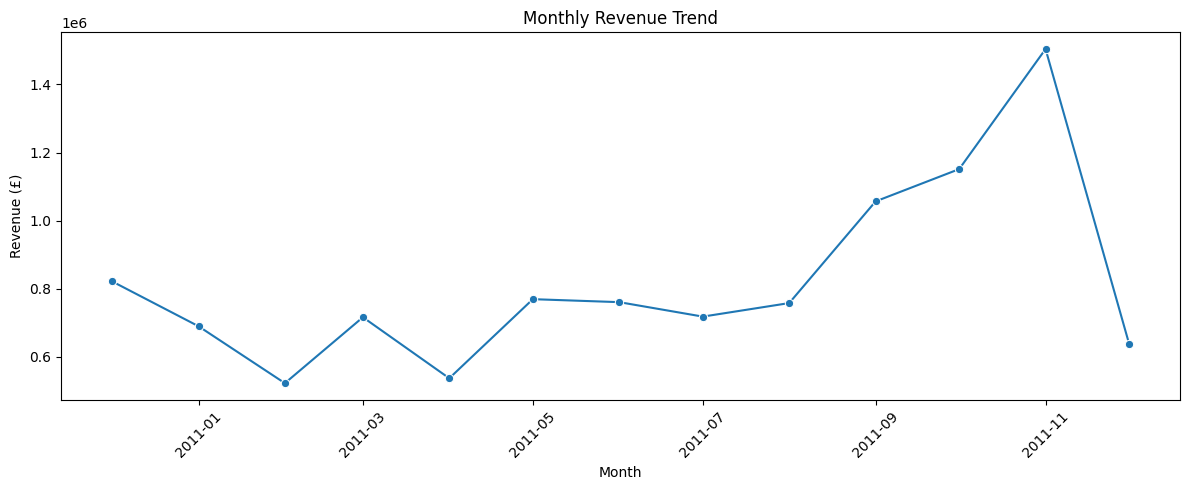

In [ ]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretasi Tren Penjualan Bulanan**

Tren revenue menunjukkan fluktuasi pada awal hingga pertengahan periode, kemudian meningkat cukup tajam mulai September 2011. Revenue tertinggi terjadi pada November 2011 sebesar £1.503.866,78, dengan 2.769 invoice dan total 751.377 unit terjual. Sebaliknya, revenue terendah terjadi pada Februari 2011 sebesar £522.545,56.

Peningkatan revenue sejak September diikuti oleh kenaikan jumlah unit terjual dan jumlah invoice, yang menunjukkan bahwa peningkatan penjualan berkaitan dengan bertambahnya volume transaksi. Pada Desember 2011, revenue tercatat sebesar £637.790,33. Namun, karena data Desember hanya mencakup transaksi hingga 9 Desember, nilai tersebut belum mewakili penjualan satu bulan penuh. Analisis lanjutan diperlukan untuk mengetahui produk dan negara yang berkontribusi terhadap peningkatan revenue pada akhir periode.

##5.Product Performance Analysis

In [ ]:
top_products = (
    df.groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index()
)

display(top_products)

,StockCode,Description,Revenue,Units_Sold
0,DOT,DOTCOM POSTAGE,206248.77,706
1,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580
4,47566,PARTY BUNTING,99445.23,18283
5,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
7,POST,POSTAGE,78101.88,3150
8,M,Manual,77750.27,6984
9,23084,RABBIT NIGHT LIGHT,66870.03,30739


In [ ]:
df[df['StockCode'] == 'DOT'][['StockCode', 'Description', 'UnitPrice']]

,StockCode,Description,UnitPrice
1765,DOT,DOTCOM POSTAGE,569.77
2961,DOT,DOTCOM POSTAGE,607.49
5273,DOT,DOTCOM POSTAGE,254.43
5362,DOT,DOTCOM POSTAGE,121.06
5502,DOT,DOTCOM POSTAGE,498.47
...,...,...,...
519923,DOT,DOTCOM POSTAGE,1008.96
520316,DOT,DOTCOM POSTAGE,1683.75
522374,DOT,DOTCOM POSTAGE,938.59
523888,DOT,DOTCOM POSTAGE,933.17


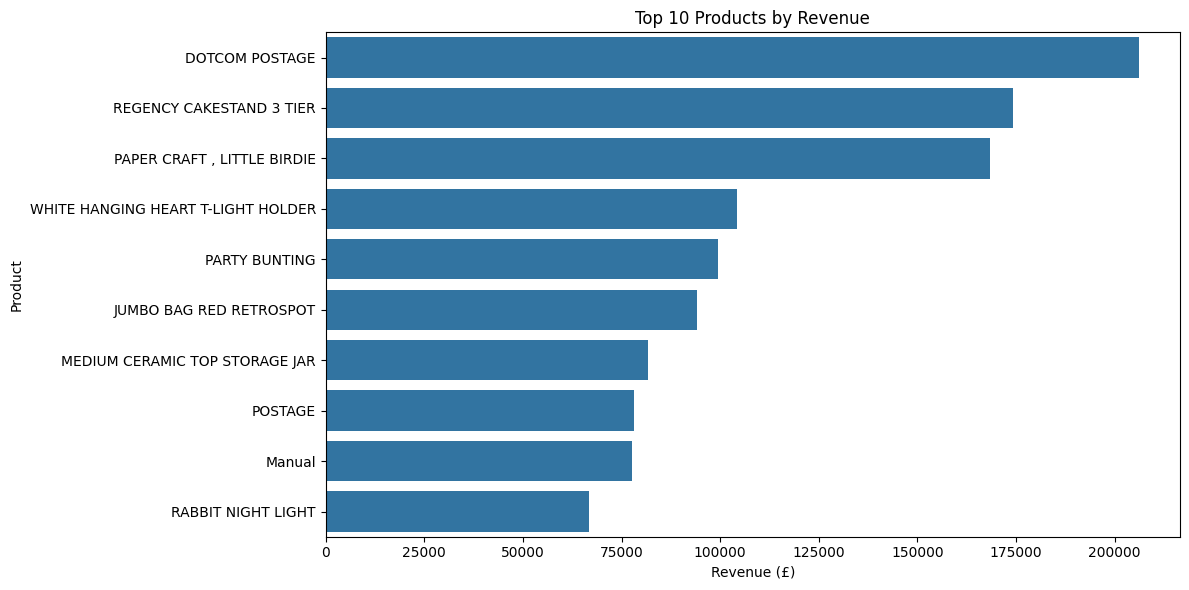

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x="Revenue",
    y="Description"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

**Interpretasi Performa Produk**

Hasil analisis menunjukkan bahwa DOTCOM POSTAGE memiliki revenue tertinggi sebesar £206.248,77. Namun, item ini merupakan biaya layanan pengiriman, bukan produk retail. Item POSTAGE dan Manual juga masuk dalam daftar sepuluh besar, sehingga hasil awal masih mencampurkan produk dengan layanan dan pencatatan khusus.

Di antara produk retail yang ditampilkan, REGENCY CAKESTAND 3 TIER memiliki revenue tertinggi sebesar £174.156,54, diikuti PAPER CRAFT, LITTLE BIRDIE sebesar £168.469,60. Produk PAPER CRAFT, LITTLE BIRDIE perlu ditinjau lebih lanjut karena jumlah penjualannya mencapai 80.995 unit dan sebelumnya ditemukan transaksi dengan kuantitas yang sangat besar.

Untuk memperoleh gambaran performa produk retail yang lebih representatif, analisis berikutnya akan mengecualikan item layanan dan pencatatan khusus dari peringkat produk.

In [ ]:
# Kode item layanan atau pencatatan khusus
non_retail_codes = ["DOT", "POST", "M"]

retail_df = df[~df["StockCode"].isin(non_retail_codes)].copy()

top_retail_products = (
    retail_df.groupby(["StockCode", "Description"])
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index()
)

display(top_retail_products)

,StockCode,Description,Revenue,Units_Sold
0,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851
1,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580
3,47566,PARTY BUNTING,99445.23,18283
4,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
6,23084,RABBIT NIGHT LIGHT,66870.03,30739
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329
8,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362
9,79321,CHILLI LIGHTS,54096.36,10302


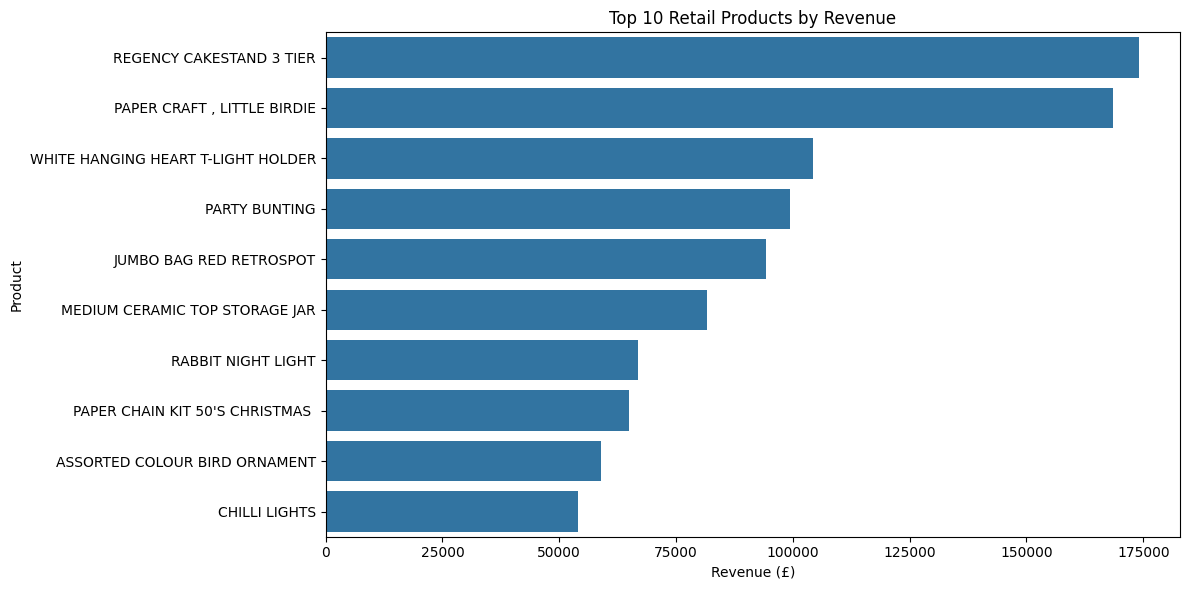

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_retail_products,
    x='Revenue',
    y='Description'
)

plt.title('Top 10 Retail Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

**Interpretasi Performa Produk Retail**

Setelah item layanan dan pencatatan khusus dikeluarkan dari peringkat, REGENCY CAKESTAND 3 TIER menjadi produk dengan revenue tertinggi sebesar £174.156,54, diikuti PAPER CRAFT, LITTLE BIRDIE sebesar £168.469,60. Posisi ketiga ditempati WHITE HANGING HEART T-LIGHT HOLDER dengan revenue £104.284,24.

PAPER CRAFT, LITTLE BIRDIE mencatat jumlah penjualan sebanyak 80.995 unit, jauh lebih tinggi dibandingkan REGENCY CAKESTAND 3 TIER yang terjual sebanyak 13.851 unit. Meskipun demikian, revenue keduanya relatif berdekatan. Hal ini menunjukkan bahwa perbedaan jumlah unit terjual tidak selalu sebanding dengan perbedaan revenue karena harga satuan setiap produk berbeda.

Hasil ini menunjukkan bahwa beberapa produk memiliki kontribusi besar terhadap pendapatan. Informasi tersebut dapat digunakan sebagai dasar untuk menentukan produk yang perlu mendapat perhatian dalam pengelolaan persediaan dan strategi penjualan.

##6.Sales Performance by Country

In [ ]:
country_sales = (
    df.groupby('Country')
    .agg(
        Revenue = ('Revenue', 'sum'),
        Units_sold = ('Quantity', 'sum'),
        Invoices = ('InvoiceNo', 'nunique')
    )
    .sort_values('Revenue', ascending = False)
    .reset_index()
)

display(country_sales.head(10))


,Country,Revenue,Units_sold,Invoices
0,United Kingdom,9001744.094,4646906,18019
1,Netherlands,285446.340,200361,94
2,EIRE,283140.520,147007,288
3,Germany,228678.400,119154,457
4,France,209625.370,112060,392
5,Australia,138453.810,83891,57
6,Spain,61558.560,27933,90
7,Switzerland,57067.600,30617,54
8,Belgium,41196.340,23237,98
9,Sweden,38367.830,36078,36


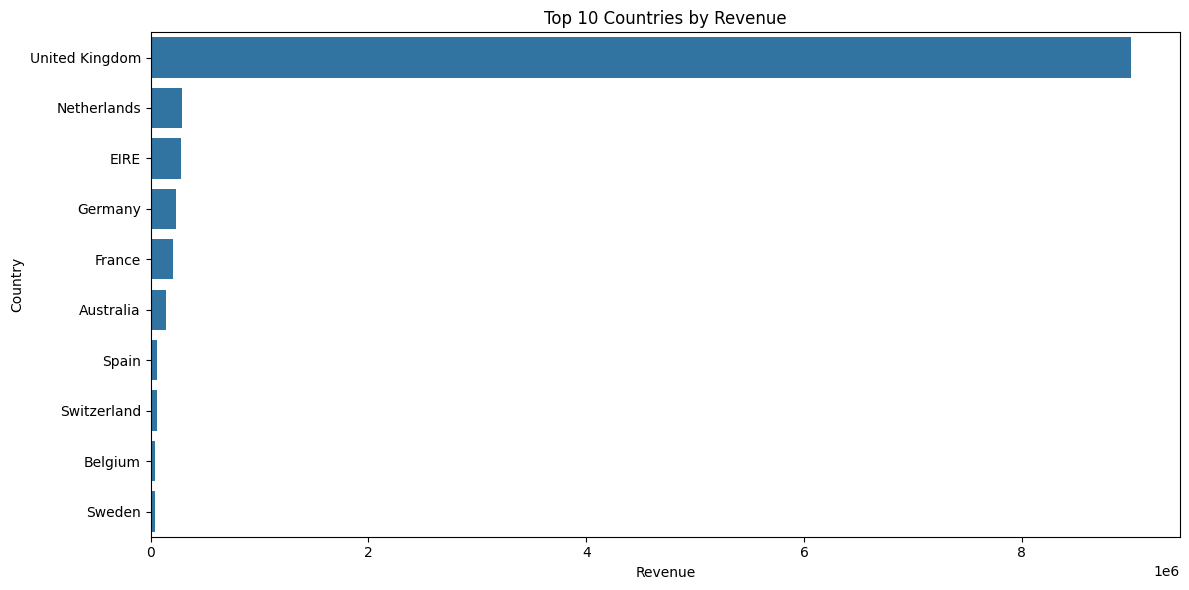

In [ ]:
top_country = country_sales.head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    data = top_country,
    x = 'Revenue',
    y = 'Country'
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

**Interpretasi Performa Penjualan Berdasarkan Negara**

Hasil analisis menunjukkan bahwa United Kingdom merupakan pasar utama dengan revenue sebesar £9.001.744,09 dan 18.019 invoice. Nilai tersebut mendominasi total revenue dataset, yaitu sekitar 84,6%. Hal ini menunjukkan bahwa aktivitas penjualan dalam dataset sangat terkonsentrasi di United Kingdom.

Netherlands menempati posisi kedua dengan revenue £285.446,34 dari 94 invoice, sedangkan EIRE berada di posisi ketiga dengan revenue £283.140,52 dari 288 invoice. Meskipun revenue kedua negara relatif berdekatan, jumlah invoice-nya berbeda cukup jauh. Temuan ini mengindikasikan adanya perbedaan rata-rata revenue per invoice antarnegara.

Hasil ini dapat menjadi dasar untuk mengevaluasi ketergantungan penjualan pada United Kingdom serta mempelajari karakteristik pasar internasional. Namun, kontribusi revenue yang besar tidak secara langsung menunjukkan tingkat profitabilitas karena data biaya operasional dan biaya produk tidak tersedia dalam dataset ini.

##7.Customer Value Analysis

In [ ]:
# Gunakan transaksi yang memiliki identitas pelanggan
customer_df = df.dropna(subset=["CustomerID"]).copy()

# Agregasi metrik pada tingkat pelanggan
customer_value = (
    customer_df.groupby("CustomerID")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Purchase_Frequency=("InvoiceNo", "nunique")
    )
    .reset_index()
)

# Hitung rata-rata revenue per invoice
customer_value["Average_Order_Value"] = (
    customer_value["Total_Revenue"]
    / customer_value["Purchase_Frequency"]
)

print("Jumlah pelanggan yang dianalisis:", len(customer_value))
display(customer_value.head())

Jumlah pelanggan yang dianalisis: 4338


,CustomerID,Total_Revenue,Purchase_Frequency,Average_Order_Value
0,12346.0,77183.60,1,77183.600000
1,12347.0,4310.00,7,615.714286
2,12348.0,1797.24,4,449.310000
3,12349.0,1757.55,1,1757.550000
4,12350.0,334.40,1,334.400000


In [ ]:
top_10_customers = (
    customer_value
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
    .copy()
)

top_10_customers["CustomerID"] = (
    top_10_customers["CustomerID"].astype(str)
)

display(top_10_customers)

,CustomerID,Total_Revenue,Purchase_Frequency,Average_Order_Value
1689,14646.0,280206.02,73,3838.438630
4201,18102.0,259657.30,60,4327.621667
3728,17450.0,194390.79,46,4225.886739
3008,16446.0,168472.50,2,84236.250000
1879,14911.0,143711.17,201,714.980945
55,12415.0,124914.53,21,5948.310952
1333,14156.0,117210.08,55,2131.092364
3771,17511.0,91062.38,31,2937.496129
2702,16029.0,80850.84,63,1283.346667
0,12346.0,77183.60,1,77183.600000


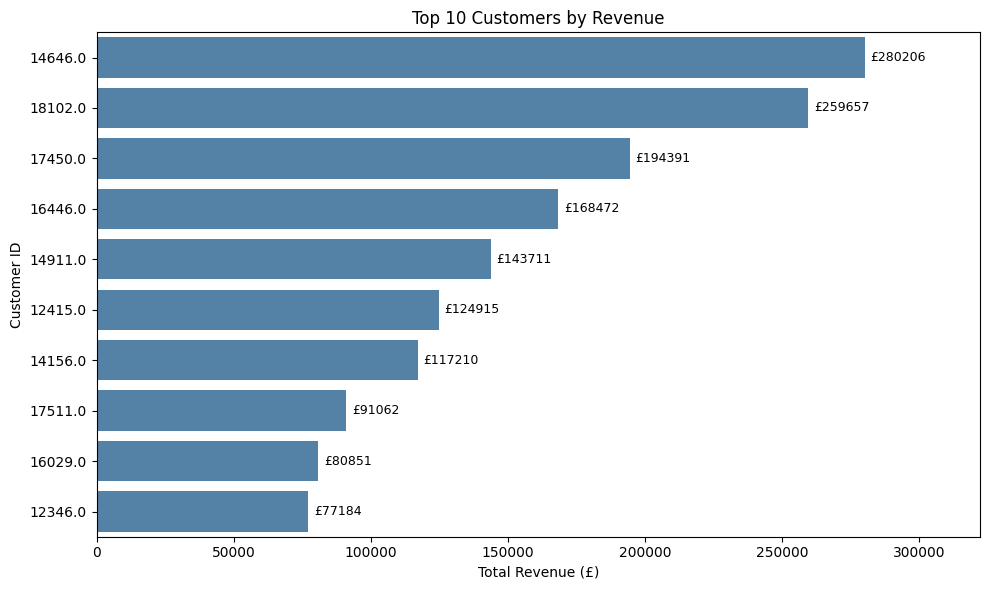

In [ ]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_10_customers,
    x="Total_Revenue",
    y="CustomerID",
    color="steelblue"
)

# Tambahkan label revenue di ujung batang
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="£%.0f",
        padding=4,
        fontsize=9
    )

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer ID")
plt.xlim(0, top_10_customers["Total_Revenue"].max() * 1.15)
plt.tight_layout()
plt.show()

# 2. RFM Analysis

## 1.Pembentukan Fitur RFM

In [ ]:
customer_df = df.dropna(subset=["CustomerID"]).copy()

snapshot_date = (
    df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = (
    customer_df.groupby("CustomerID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (snapshot_date - x.max().normalize()).days
        ),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)


print("Tanggal acuan:", snapshot_date.date())
print("Jumlah pelanggan:", len(rfm))

display(rfm.head())

Tanggal acuan: 2011-12-10
Jumlah pelanggan: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40


**Interpretasi Hasil**

Pembentukan fitur RFM menghasilkan data untuk 4.338 pelanggan yang memiliki identitas pelanggan (`CustomerID`). Setiap pelanggan memiliki tiga metrik, yaitu Recency, Frequency, dan Monetary.

Tanggal acuan ditetapkan pada 10 Desember 2011, satu hari setelah tanggal transaksi terakhir dalam dataset. Hasil awal menunjukkan adanya perbedaan perilaku pembelian antarpelanggan, baik dari waktu transaksi terakhir, frekuensi pembelian, maupun total nilai pembelian.

Sebagai contoh, Customer 12347 memiliki Recency 3 hari dan Frequency 7, sedangkan Customer 12346 memiliki Frequency 1 dengan Monetary sebesar £77.183,60. Perbedaan ini menunjukkan bahwa pelanggan dengan nilai pembelian tinggi belum tentu sering bertransaksi.

Selanjutnya, statistik deskriptif dan distribusi RFM akan diperiksa untuk memahami pola seluruh pelanggan serta mengidentifikasi nilai ekstrem sebelum proses segmentasi.

In [ ]:
# Menyimpan dataset RFM asli
rfm_original_path = '/content/drive/MyDrive/ecommerce-sales-customer-analytics/data/rfm_original.csv'

rfm.to_csv(rfm_original_path, index=False)

print('Dataset RFM asli berhasil disimpan.')
print('Lokasi:', rfm_original_path)
print('Ukuran dataset:', rfm.shape)

display(rfm.head())

Dataset RFM asli berhasil disimpan.
Lokasi: /content/drive/MyDrive/ecommerce-sales-customer-analytics/data/rfm_original.csv
Ukuran dataset: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,3,7,4310.00
2,12348.0,76,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,311,1,334.40


## 2.Pemeriksaan Statistik Deskriptif

Statistik deskriptif digunakan untuk memahami karakteristik data RFM secara keseluruhan. Pemeriksaan ini mencakup nilai minimum, maksimum, rata-rata, median yang diwakili oleh kuartil kedua, dan sebaran data.


In [ ]:
display(
    rfm[["Recency", "Frequency", "Monetary"]]
    .describe()
    .round(2)
)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,93.06,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.75,5.00,1660.60
max,374.00,209.00,280206.02


##3.Visualisasi Distribusi RFM

Visualisasi distribusi digunakan untuk melihat pola penyebaran nilai Recency, Frequency, dan Monetary secara lebih jelas. Grafik membantu mengidentifikasi kemencengan distribusi, konsentrasi nilai pelanggan, serta kemungkinan nilai ekstrem yang sulit terlihat hanya dari tabel statistik.

Hasil visualisasi akan menjadi dasar untuk menentukan apakah fitur memerlukan transformasi sebelum digunakan dalam proses segmentasi pelanggan.

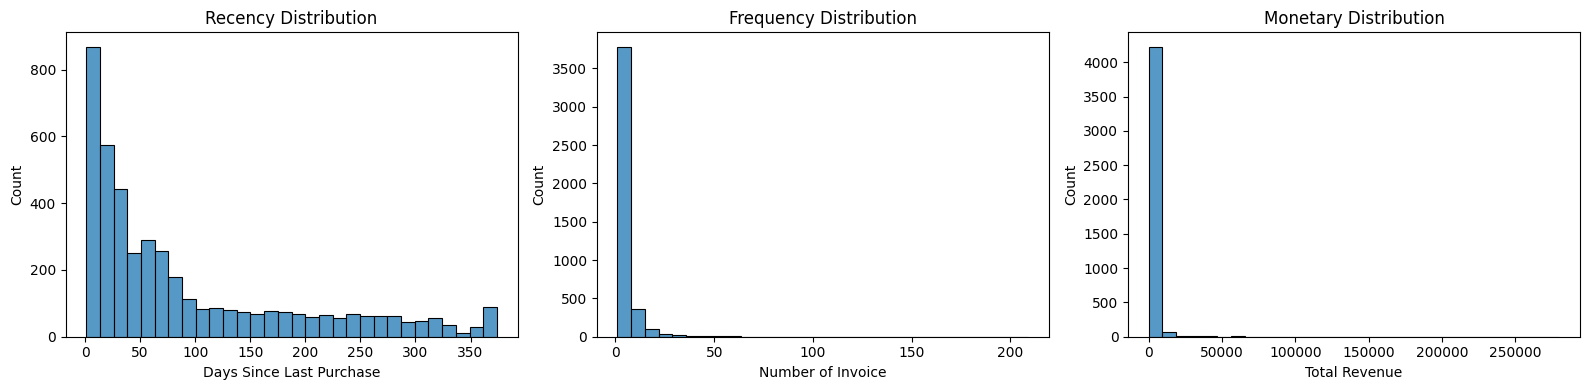

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=rfm, x='Recency', bins=30, ax=axes[0])
axes[0].set_title('Recency Distribution')
axes[0].set_xlabel('Days Since Last Purchase')

sns.histplot(data=rfm, x='Frequency', bins=30, ax=axes[1])
axes[1].set_title('Frequency Distribution')
axes[1].set_xlabel('Number of Invoice')

sns.histplot(data=rfm, x='Monetary', bins=30, ax=axes[2])
axes[2].set_title('Monetary Distribution')
axes[2].set_xlabel('Total Revenue')

plt.tight_layout()
plt.show()

A. Recency Distribution
- Sebagian besar pelanggan memiliki Recency yang relatif rendah, artinya mereka bertransaksi dalam periode yang lebih dekat dengan tanggal acuan.
- Jumlah pelanggan semakin sedikit ketika jarak dari transaksi terakhir semakin panjang.
- Terdapat pelanggan dengan Recency mendekati 374 hari yang sudah lama tidak bertransaksi.

  **Kesimpulan: distribusi Recency menceng ke kanan. Ada pelanggan yang baru bertransaksi dan ada kelompok pelanggan yang sudah lama tidak aktif.**

B. Frequency Distribution
- Sebagian besar pelanggan hanya memiliki sedikit invoice.
- Jumlah pelanggan menurun tajam ketika frekuensi transaksi meningkat.

  **Kesimpulan: perilaku pembelian pelanggan tidak merata. Mayoritas bertransaksi relatif sedikit, sedangkan sebagian kecil pelanggan bertransaksi jauh lebih sering.**

C. Monetary Distribution

- Sebagian besar pelanggan memiliki total revenue yang relatif rendah dibandingkan nilai maksimum.
- Terdapat sejumlah kecil pelanggan dengan Monetary yang sangat besar.
- Nilai maksimum mencapai £280.206,02, jauh di atas median £668,57 yang kita temukan sebelumnya.

  **Kesimpulan: Monetary memiliki kemencengan paling mencolok. Nilai ekstrem dapat membuat skala fitur ini mendominasi perhitungan jarak pada K-Means.**






## 4.Analisis Nilai Ekstrem dan Penentuan Preprocessing

Visualisasi distribusi menunjukkan bahwa Recency, Frequency, dan Monetary memiliki distribusi yang menceng ke kanan. Sebagian besar pelanggan memiliki frekuensi dan total nilai pembelian yang relatif rendah, sedangkan sebagian kecil pelanggan memiliki nilai yang jauh lebih tinggi.

Kondisi ini perlu diperhatikan karena K-Means menggunakan jarak untuk mengelompokkan pelanggan. Perbedaan skala dan nilai ekstrem dapat memengaruhi pembentukan kelompok.

Oleh karena itu, transformasi log akan dipertimbangkan untuk Frequency dan Monetary guna mengurangi kemencengan distribusi. Selanjutnya, fitur RFM akan distandardisasi agar setiap fitur memiliki skala yang sebanding. Nilai ekstrem tidak langsung dihapus karena dapat merepresentasikan perilaku pelanggan yang nyata.

##5.Visualisasi Boxplot RFM

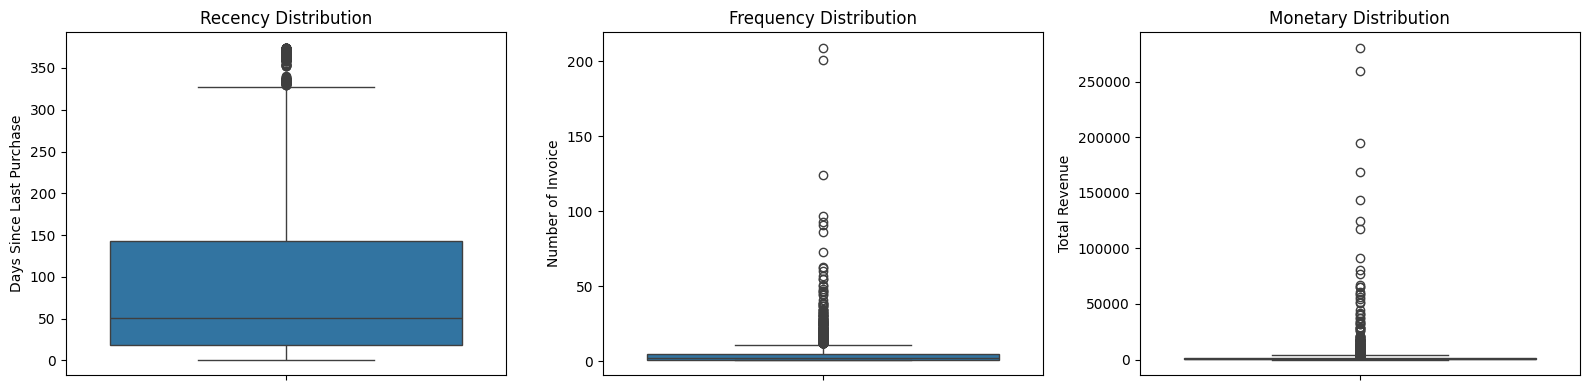

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(y=rfm['Recency'], ax=axes[0])
axes[0].set_title('Recency Distribution')
axes[0].set_ylabel('Days Since Last Purchase')

sns.boxplot(y=rfm['Frequency'], ax=axes[1])
axes[1].set_title('Frequency Distribution')
axes[1].set_ylabel('Number of Invoice')

sns.boxplot(y=rfm['Monetary'], ax=axes[2])
axes[2].set_title('Monetary Distribution')
axes[2].set_ylabel('Total Revenue')

plt.tight_layout()
plt.show()

**Interpretasi Hasil Boxplot**

Hasil boxplot menunjukkan adanya kandidat outlier pada ketiga fitur RFM. Pada Recency, beberapa pelanggan memiliki jarak transaksi terakhir yang lebih panjang daripada mayoritas pelanggan. Pada Frequency, terdapat pelanggan dengan jumlah transaksi yang jauh lebih tinggi dibandingkan pelanggan lainnya. Sementara itu, Monetary menunjukkan nilai ekstrem yang paling mencolok, dengan beberapa pelanggan menghasilkan total revenue yang sangat besar.

Nilai-nilai tersebut tidak langsung dianggap sebagai kesalahan data karena dapat mencerminkan perbedaan perilaku pelanggan yang nyata. Namun, nilai ekstrem perlu diperhatikan karena dapat memengaruhi hasil segmentasi menggunakan K-Means.

Berdasarkan temuan ini, transformasi log akan diterapkan pada Frequency dan Monetary untuk mengurangi kemencengan distribusi. Selanjutnya, seluruh fitur RFM akan distandardisasi agar memiliki skala yang sebanding sebelum digunakan dalam pemodelan.

#Feature Engineering & Preprocessing

## 1.Transformasi Fitur RFM

Transformasi log digunakan untuk mengurangi kemencengan distribusi Frequency dan Monetary akibat perbedaan nilai yang besar antarpelanggan. Transformasi dilakukan menggunakan `log1p()`, yaitu logaritma natural dari nilai ditambah satu.

Recency tidak ditransformasi pada tahap ini. Setelah transformasi selesai, distribusi fitur akan diperiksa kembali sebelum dilakukan standardisasi.

In [ ]:
rfm_transformed = rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary']].copy()

rfm_transformed['Frequency_log'] = np.log1p(rfm_transformed['Frequency'])
rfm_transformed['Monetary_log'] = np.log1p(rfm_transformed['Monetary'])

display(
    rfm_transformed[
        ['Frequency', 'Frequency_log', 'Monetary', 'Monetary_log']
    ].head()
)

,Frequency,Frequency_log,Monetary,Monetary_log
0,1,0.693147,77183.60,11.253955
1,7,2.079442,4310.00,8.368925
2,4,1.609438,1797.24,7.494564
3,1,0.693147,1757.55,7.472245
4,1,0.693147,334.40,5.815324


###Pemeriksaan Distribusi Setelah Transformasi

Pada tahap ini, distribusi Frequency dan Monetary setelah transformasi log dibandingkan secara visual dengan distribusi sebelumnya. Tujuannya adalah menilai apakah transformasi membuat sebaran data lebih merata dan mengurangi kemencengan yang terlihat pada analisis sebelumnya.

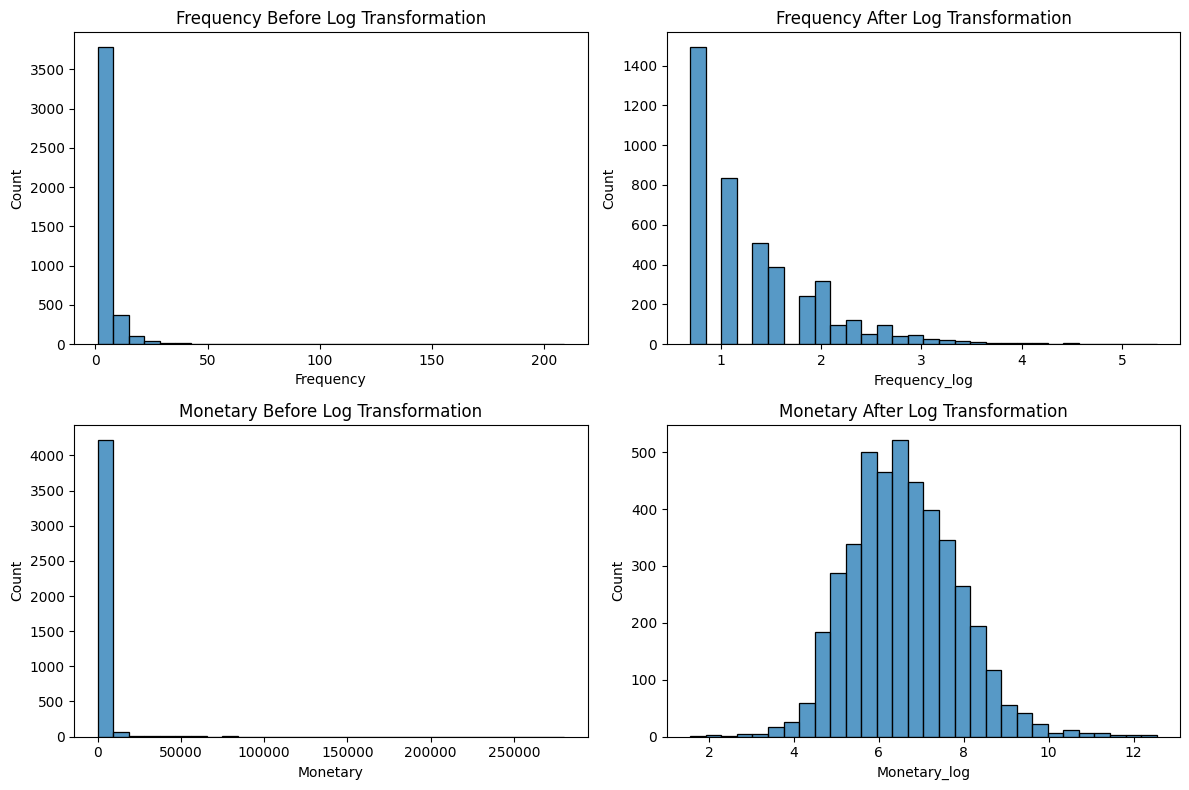

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=rfm, x='Frequency', bins=30, ax=axes[0, 0])
axes[0, 0].set_title('Frequency Before Log Transformation')

sns.histplot(data=rfm_transformed, x='Frequency_log', bins=30, ax=axes[0, 1])
axes[0, 1].set_title('Frequency After Log Transformation')

sns.histplot(data=rfm, x='Monetary', bins=30, ax=axes[1, 0])
axes[1, 0].set_title('Monetary Before Log Transformation')

sns.histplot(data=rfm_transformed, x='Monetary_log', bins=30, ax=axes[1, 1])
axes[1, 1].set_title('Monetary After Log Transformation')

plt.tight_layout()
plt.show()

**Interpretasi Hasil Transformasi Log**

Perbandingan distribusi sebelum dan sesudah transformasi menunjukkan bahwa penggunaan `log1p()` membantu mengurangi kemencengan pada Frequency dan Monetary. Perubahan paling jelas terlihat pada Monetary, yang sebelumnya sangat terkonsentrasi di dekat nilai rendah akibat adanya sejumlah kecil pelanggan dengan total revenue sangat tinggi.

Frequency juga menunjukkan rentang nilai yang lebih proporsional setelah transformasi, meskipun distribusinya masih menceng ke kanan. Hal ini tidak menjadi masalah karena tujuan transformasi adalah mengurangi pengaruh perbedaan nilai yang ekstrem, bukan memaksakan distribusi menjadi normal.

Berdasarkan hasil tersebut, Frequency dan Monetary akan menggunakan nilai hasil transformasi, sedangkan Recency tetap menggunakan nilai aslinya. Ketiga fitur kemudian akan distandardisasi sebelum digunakan dalam pemodelan K-Means.

##2.Standardisasi Fitur RFM

Standardisasi dilakukan untuk menyamakan skala Recency, Frequency, dan Monetary agar tidak ada fitur yang mendominasi perhitungan jarak hanya karena memiliki rentang nilai yang lebih besar.

Pada tahap ini, Recency menggunakan nilai asli, sedangkan Frequency dan Monetary menggunakan nilai hasil transformasi log. Standardisasi dilakukan menggunakan `StandardScaler`, yang mengubah setiap fitur agar memiliki rata-rata mendekati 0 dan standar deviasi mendekati 1.

In [ ]:
from sklearn.preprocessing import StandardScaler

rfm_features=rfm_transformed[
    ['Recency', 'Frequency_log', 'Monetary_log']
].copy()

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

rfm_scaled=pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index = rfm_features.index
)

display(rfm_scaled.head())

print('Rata-rata setiap fitur:')
display(rfm_scaled.mean().round(3))

print('Standar deviasi setiap fitur:')
display(rfm_scaled.std(ddof=0).round(3))

,Recency,Frequency,Monetary
0,2.329388,-0.955214,3.707716
1,-0.900588,1.074425,1.414903
2,-0.170593,0.386304,0.720024
3,-0.740589,-0.955214,0.702287
4,2.179389,-0.955214,-0.614514


Rata-rata setiap fitur:


,0
Recency,-0.0
Frequency,-0.0
Monetary,-0.0


Standar deviasi setiap fitur:


,0
Recency,1.0
Frequency,1.0
Monetary,1.0


##3.Pemeriksaan Hasil Preprocessing

Setelah transformasi log dan standardisasi, data diperiksa kembali untuk memastikan seluruh fitur yang akan digunakan dalam segmentasi tersedia dan tidak memiliki nilai kosong.


In [ ]:
print('Ukuran dataset:', rfm_scaled.shape)
print('Jumlah nilai kosong:', rfm_scaled.isnull().sum().sum())
print('Jumlah nilai tak hingga:', np.isinf(rfm_scaled).sum().sum())

display(rfm_scaled.describe().round(3))

Ukuran dataset: (4338, 3)
Jumlah nilai kosong: 0
Jumlah nilai tak hingga: 0


,Recency,Frequency,Monetary
count,4338.000,4338.000,4338.000
mean,-0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-0.921,-0.955,-3.998
25%,-0.751,-0.955,-0.684
50%,-0.421,-0.362,-0.065
75%,0.497,0.653,0.657
max,2.809,5.859,4.732


**Interpretasi Hasil Pemeriksaan Preprocessing**

Hasil pemeriksaan menunjukkan bahwa dataset RFM memiliki 4.338 pelanggan dan tiga fitur yang siap digunakan untuk segmentasi. Tidak ditemukan nilai kosong maupun nilai tak hingga pada fitur hasil preprocessing.

Rata-rata setiap fitur mendekati nol dan standar deviasinya sebesar satu. Hasil ini menunjukkan bahwa standardisasi menggunakan `StandardScaler` telah berjalan sesuai harapan.

Meskipun demikian, masih terdapat beberapa nilai yang relatif jauh dari rata-rata. Nilai tersebut tetap dipertahankan karena dapat merepresentasikan karakteristik pelanggan yang berbeda. Dataset selanjutnya akan disimpan untuk digunakan pada tahap pemodelan segmentasi pelanggan.

In [ ]:
rfm_modeling = rfm_transformed[['CustomerID']].copy()

rfm_modeling['Recency'] = rfm_scaled['Recency']
rfm_modeling['Frequency'] = rfm_scaled['Frequency']
rfm_modeling['Monetary'] = rfm_scaled['Monetary']

output_path = '/content/drive/MyDrive/ecommerce-sales-customer-analytics/data/rfm_modeling.csv'
rfm_modeling.to_csv(output_path, index=False)

print('Dataset berhasil disimpan.')
print('Lokasi:', output_path)
print('Ukuran dataset:', rfm_modeling.shape)

display(rfm_modeling.head())

Dataset berhasil disimpan.
Lokasi: /content/drive/MyDrive/ecommerce-sales-customer-analytics/data/rfm_modeling.csv
Ukuran dataset: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346.0,2.329388,-0.955214,3.707716
1,12347.0,-0.900588,1.074425,1.414903
2,12348.0,-0.170593,0.386304,0.720024
3,12349.0,-0.740589,-0.955214,0.702287
4,12350.0,2.179389,-0.955214,-0.614514


## 5. Kesimpulan EDA dan Feature Engineering

Analisis eksplorasi data menunjukkan adanya perbedaan pola penjualan berdasarkan waktu, produk, negara, dan pelanggan. Pada analisis pelanggan, fitur RFM digunakan untuk menggambarkan waktu transaksi terakhir, frekuensi pembelian, dan total nilai pembelian.

Pemeriksaan distribusi menunjukkan bahwa Frequency dan Monetary memiliki kemencengan ke kanan serta nilai ekstrem. Oleh karena itu, transformasi log diterapkan pada kedua fitur tersebut, kemudian seluruh fitur RFM distandardisasi menggunakan `StandardScaler`.

Dataset hasil preprocessing berisi 4.338 pelanggan dan tiga fitur RFM yang telah diproses. Dataset disimpan dalam file `rfm_modeling.csv` dan akan digunakan sebagai input untuk tahap segmentasi pelanggan menggunakan K-Means pada notebook berikutnya.